# 00 · Inventory and setup

**Question:** which data do we test the ATL03 v007 reclassification on, and is everything reachable?

This notebook:
1. records the code, config and SlideRule versions used;
2. finds G-LiHT CHM + DTM strips in Alaska (LP DAAC `GLCHMT`, `GLDTMT` v001) and picks validation tiles in **interior Alaska** and on the **Kenai Peninsula** by G-LiHT coverage (2018 preferred, the closest to ICESat-2);
3. lists the Seward Peninsula 2024 field transects (tundra and shrub reference);
4. counts the ATL03 **v007** granules (looked up in CMR by name, June–September) over each site.

Outputs (in `work_dir/inventory/`): `glihit_strips_alaska.parquet`, `selected_tiles.parquet`, `seward_sites.parquet`, `granules.csv`.

Plan: `docs/atl03_reclassification_plan.md` §3–4.0.

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box
warnings.filterwarnings("ignore", category=FutureWarning)

REPO = Path.cwd().resolve().parents[1]          # notebooks/atl03_reclass -> repo root
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val, plot_style as ps
ps.apply()   # shared figure style; vegetation-height colormap ps.HEIGHT_CMAP; ESRI Light Gray basemap ps.add_basemap

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.6.yaml")   # profile auto: 'maap' on MAAP ADE, else 'adapt'
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)   # shared inputs: downloads, fetched photons, inventories
RUN = WORK / "runs" / f"v{cfg['version']}"; RUN.mkdir(parents=True, exist_ok=True)   # everything that depends on the config version
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)
print("profile:", cfg["profile"], "| config", cfg["version"], cfg["config_sha1"], "| work_dir:", WORK, "| run_dir:", RUN)
print(json.dumps(ipl.provenance(cfg), indent=1))

profile: adapt | config 0.6 40e8f82a4112 | work_dir: /explore/nobackup/people/pmontesa/atl03_reclass | run_dir: /explore/nobackup/people/pmontesa/atl03_reclass/runs/v0.6


{
 "repo": "circumpolar_boreal_trends",
 "git_commit": "0cecd4e",
 "git_dirty_lib_or_config": true,
 "config_version": "0.6",
 "config_sha1": "40e8f82a4112",
 "sliderule_client": "5.6.3",
 "processed_utc": "2026-10-18T12:20:52"
}


## 1. SlideRule

In [2]:
sliderule = ipl.sliderule_init()
v = sliderule.get_version()
print("client", sliderule.__version__)
print({k: v[k].get("version", v[k]) if isinstance(v.get(k), dict) else v.get(k) for k in list(v)[:6]})

client 5.6.3
{'server': 'v5.6.3', 'client': 'v5.6.3'}


## 2. Boreal tiles

In [3]:
tiles_fn = Path(cfg["paths"]["boreal_tiles"])
if not tiles_fn.exists():   # ADAPT: copy the v004 tile grid next to the outputs once
    import shutil; tiles_fn.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy("/explore/nobackup/people/pmontesa/userfs02/projects/above_icesat2/boreal_tiles/boreal_tiles_v004.gpkg", tiles_fn)
tiles = gpd.read_file(tiles_fn)
tiles["tile_num"] = tiles["tile_num"].astype(int)
tiles4326 = tiles.to_crs(4326)
print(len(tiles), "tiles;", tiles.crs)

5346 tiles; PROJCS["unnamed",GEOGCS["GRS 1980(IUGG, 1980)",DATUM["unknown",SPHEROID["GRS80",6378137,298.257222101],TOWGS84[0,0,0,0,0,0,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["standard_parallel_1",50],PARAMETER["standard_parallel_2",70],PARAMETER["latitude_of_center",40],PARAMETER["longitude_of_center",180],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["Meter",1],AXIS["Easting",EAST],AXIS["Northing",NORTH]]


## 3. G-LiHT strips in Alaska

Each G-LiHT granule is one flight-line strip of 1 m CHM (and a matching DTM). Alaska has flights only in **2014** and **2018**,
so every comparison with ICESat-2 (2019 onward) spans at least one growing season and needs a disturbance screen (notebook 02).

In [4]:
INV = WORK / "inventory"; INV.mkdir(exist_ok=True)
strips_fn = INV / "glihit_strips_alaska.parquet"
if strips_fn.exists():
    strips = gpd.read_parquet(strips_fn)
else:
    strips = ref.glihit_pairs((-170, 55, -140, 72))
    strips.to_parquet(strips_fn)
print(len(strips), "CHM+DTM strip pairs")
strips.groupby("year").size()

12677 CHM+DTM strip pairs


year
2014    3449
2018    9228
dtype: int64

In [5]:
# tile x strip overlap (area of strips in each tile, km2), by year and region
st = strips.to_crs(tiles.crs)
st["area_km2"] = st.area / 1e6
ov = gpd.overlay(st[["stem", "year", "geometry"]], tiles[["tile_num", "geometry"]], how="intersection")
ov["area_km2"] = ov.area / 1e6
by_tile = ov.pivot_table(index="tile_num", columns="year", values="area_km2", aggfunc="sum", fill_value=0)
by_tile.columns = [f"glihit_km2_{c}" for c in by_tile.columns]
cent = tiles4326.set_index("tile_num").geometry.centroid
by_tile["lon"], by_tile["lat"] = cent.reindex(by_tile.index).x, cent.reindex(by_tile.index).y

def region(lon, lat):
    if -152.6 <= lon <= -148.5 and 59.3 <= lat <= 61.4: return "Kenai"
    if -152.0 <= lon <= -141.0 and 63.5 <= lat <= 67.5: return "Interior"   # north of the Alaska Range
    return "other"
by_tile["region"] = [region(x, y) for x, y in zip(by_tile.lon, by_tile.lat)]
by_tile.sort_values("glihit_km2_2018", ascending=False).head(15)

/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_1311845/1158922563.py:8: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  cent = tiles4326.set_index("tile_num").geometry.centroid


,glihit_km2_2014,glihit_km2_2018,lon,lat,region
tile_num,,,,,
3741,0.000000,2332.549659,-149.871550,62.194479,other
3648,0.000000,1960.683475,-147.500854,62.547510,other
3649,0.000000,1938.373726,-145.948232,62.169397,other
3835,7.971325,1869.126664,-150.615121,61.475903,other
3647,148.075803,1833.750556,-149.092127,62.909170,other
3555,0.000000,1793.681184,-145.076976,62.862226,other
3742,0.000000,1756.579649,-148.307942,61.841238,other
3556,290.555159,1464.882820,-143.540189,62.459180,other
3650,0.000000,1304.719210,-144.434467,61.775423,other


### Tile selection rule
Per region, the two tiles with the most **2018** G-LiHT strip area (closest to ICESat-2), if the best tile has at least
200 km² of 2018 strips; otherwise the two tiles with the most **2014** area. Interior = north of the Alaska Range (≥ 63.5°N).

In [6]:
sel = []
for reg in ["Interior", "Kenai"]:
    t = by_tile[by_tile.region == reg]
    col = "glihit_km2_2018" if t.get("glihit_km2_2018", pd.Series(0.0)).max() >= 200 else "glihit_km2_2014"
    sel += [(i, reg, col.split("_")[-1]) for i in t.sort_values(col, ascending=False).index[:2]]
selected = tiles4326.set_index("tile_num").loc[[s[0] for s in sel]].reset_index()
selected["region"] = [s[1] for s in sel]
selected["glihit_year"] = [int(s[2]) for s in sel]
selected = selected.merge(by_tile.reset_index()[["tile_num"] + [c for c in by_tile if c.startswith("glihit_km2")]], on="tile_num")
selected.to_parquet(INV / "selected_tiles.parquet")
selected.drop(columns="geometry")

,tile_num,tile_version,tile_group,map_version,region,glihit_year,glihit_km2_2014,glihit_km2_2018
0,3457,version 1,north america west,NaN,Interior,2018,8887.774315,446.237549
1,3553,version 1,north america west,NaN,Interior,2018,3244.173814,391.952350
2,3836,version 1,north america west,NaN,Kenai,2018,0.000000,806.438841
3,3928,version 1,north america west,NaN,Kenai,2018,389.328692,785.492737


## 4. Seward Peninsula 2024 field transects

In [7]:
seward, field = ref.seward_inventory(cfg["paths"]["seward_dir"])
seward.to_parquet(INV / "seward_sites.parquet")
seward_tiles = gpd.sjoin(seward[["site", "geometry"]], tiles4326[["tile_num", "geometry"]], predicate="intersects")
print(field.groupby("site").size().to_string())
seward.drop(columns="geometry").merge(seward_tiles[["site", "tile_num"]], on="site")

/explore/nobackup/people/pmontesa/envs/atl03reclass/lib/python3.11/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'sew_pen_field_data_2024.gpkg': 'sew_pen_2024_points_wHgts_from_lines_from_uas_rgb_v20240821' (default), 'sew_pen_2024_lines_from_uas_rgb_v20240821', 'sew_pen_2024_geotagged_photos'. Specify layer parameter to avoid this warning.
  result = read_func(


site
Council_01     140
Council_02     150
Kougarok_01     50
Kougarok_02    200
Kougarok_03    100
Kougarok_04    150
Kougarok_05    100
Kougarok_06    150
Teller_01      100


,site,dsm,dtm,atl03_field_extract,n_field_points,tile_num
0,council_01,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,140,3733
1,council_02,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,150,3733
2,kougarok_01,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,50,3638
3,kougarok_02,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,200,3732
4,kougarok_03,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,100,3638
5,kougarok_04,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,150,3638
6,kougarok_05,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,100,3638
7,kougarok_06,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,150,3638
8,teller_01,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,/explore/nobackup/people/pmontesa/userfs02/pro...,100,3732


## 5. Map

/explore/nobackup/people/pmontesa/.nccstmp/ipykernel_1311845/3642228110.py:9: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gpd.GeoSeries(seward.geometry.dropna().centroid, crs=4326).to_crs(AK).plot(ax=ax, color="royalblue", markersize=40, marker="^", zorder=5)


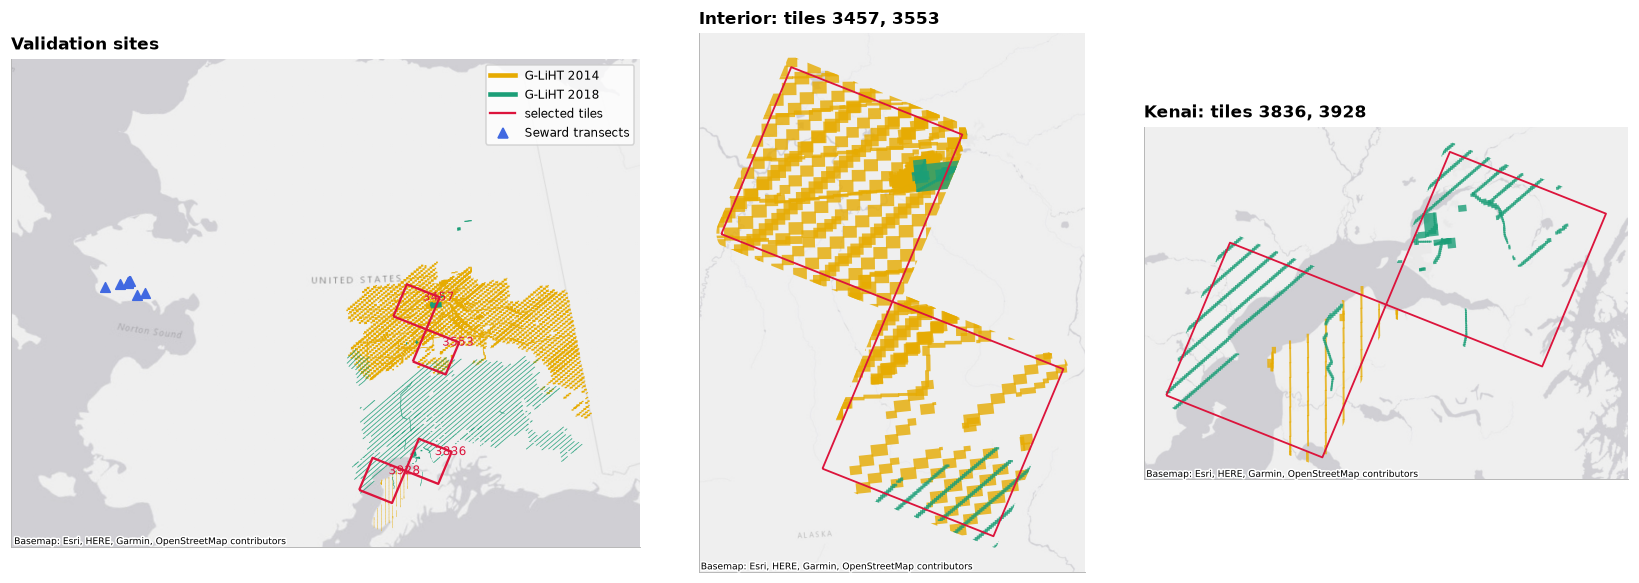

In [8]:
# Maps in Alaska Albers (EPSG:3338) on the ESRI Light Gray basemap (lib/plot_style.py)
AK = 3338
GL_COLORS = {2014: "#e6ab02", 2018: "#1b9e77"}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax = axes[0]
for yr, c in GL_COLORS.items():
    strips[strips.year == yr].to_crs(AK).plot(ax=ax, color=c, lw=0.6, zorder=3)
selected.to_crs(AK).boundary.plot(ax=ax, color="crimson", lw=1.5, zorder=4)
gpd.GeoSeries(seward.geometry.dropna().centroid, crs=4326).to_crs(AK).plot(ax=ax, color="royalblue", markersize=40, marker="^", zorder=5)
for _, r in selected.to_crs(AK).iterrows():
    ax.annotate(f"{r.tile_num}", (r.geometry.centroid.x, r.geometry.centroid.y), xytext=(4, 4), textcoords="offset points",
                fontsize=8, color="crimson", zorder=6)
xmin, ymin, xmax, ymax = gpd.GeoSeries([box(-168, 58.5, -140, 70)], crs=4326).to_crs(AK).total_bounds
ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
ps.add_basemap(ax, AK); ps.map_axes(ax, "Validation sites")
ax.legend(handles=[plt.Line2D([], [], color=GL_COLORS[2014], lw=3), plt.Line2D([], [], color=GL_COLORS[2018], lw=3),
                   plt.Line2D([], [], color="crimson", lw=1.5), plt.Line2D([], [], color="royalblue", marker="^", ls="")],
          labels=["G-LiHT 2014", "G-LiHT 2018", "selected tiles", "Seward transects"], loc="upper right", frameon=True)
for ax, reg in zip(axes[1:], ["Interior", "Kenai"]):
    s = selected[selected.region == reg]
    if not len(s): continue
    cl = gpd.clip(strips, s.geometry.union_all().buffer(0.05))
    for yr, c in GL_COLORS.items():
        if (cl.year == yr).any(): cl[cl.year == yr].to_crs(AK).plot(ax=ax, color=c, alpha=0.8, zorder=3)
    s.to_crs(AK).boundary.plot(ax=ax, color="crimson", lw=1.2, zorder=4)
    ps.add_basemap(ax, AK); ps.map_axes(ax, f"{reg}: tiles {', '.join(map(str, s.tile_num))}")
fig.tight_layout(); fig.savefig(FIG / "00_inventory_map.png")

## 6. ATL03 v007 granules over each site (June–September)

In [9]:
rows = []
yrs_val = {2018: [2019, 2020], 2014: [2019]}            # closest ICESat-2 growing seasons to the ALS year
for _, r in selected.iterrows():
    g = ipl.granules_from_cmr(r.geometry, yrs_val[r.glihit_year], cfg["icesat2"]["months"], release=cfg["icesat2"]["release"])
    rows += [{"site": f"tile_{r.tile_num}", "region": r.region, "granule": x} for x in g]
for _, r in seward.iterrows():
    if r.geometry is None: continue
    g = ipl.granules_from_cmr(r.geometry.buffer(0.01), cfg["icesat2"]["years"], cfg["icesat2"]["months"], release=cfg["icesat2"]["release"])
    rows += [{"site": r.site, "region": "Seward", "granule": x} for x in g]
gran = pd.DataFrame(rows)
gran["release"] = gran["granule"].str.split("_").str[3]
gran.to_csv(INV / "granules.csv", index=False)
gran.groupby(["region", "site"]).agg(n_granules=("granule", "size"), releases=("release", lambda s: ",".join(sorted(set(s)))))

n_granules releases
region   site                            
Interior tile_3457            62      007
         tile_3553            60      007
Kenai    tile_3836            52      007
         tile_3928            50      007
Seward   council_01           26      007
         council_02           13      007
         kougarok_01          29      007
         kougarok_02          20      007
         kougarok_03          21      007
         kougarok_04          22      007
         kougarok_05          22      007
         kougarok_06          21      007
         teller_01            19      007

## Results
- Validation tiles and their G-LiHT coverage are in the table above and `selected_tiles.parquet`.
- Every granule listed is release **007** (the `releases` column), named explicitly in each SlideRule request.
- Next: notebook 01 (Seward transects), notebook 02 (reference photon labels on the G-LiHT tiles).